# Tester votre propre image avec vos modèles YOLO (Segmentation & Orientation OBB)

Ce notebook vous permet de **sélectionner ou renseigner votre propre image** et d'afficher immédiatement :
- **Bloc 1** : Sélection de votre image (via boîte de dialogue Windows ou chemin direct) + chemins de vos modèles (`best.pt`).
- **Bloc 2** : Chargement du modèle (Segmentation, Détection ou OBB) et de votre image.
- **Bloc 3** : Exécution de la prédiction sur votre image (boîtes orientées + angles en degrés pour OBB, ou masques + squelette/extrémités/intersections pour Segmentation).
- **Bloc 4** : Affichage visuel comparatif (Originale vs Résultat), tableau récapitulatif et sauvegarde de l'image annotée.

## Bloc 1 — Choisir votre propre image et votre modèle (`best.pt`)

In [18]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# -------------------------------------------------------------------------
# OPTION A : Mettez le chemin de VOTRE propre image ici
# Exemple : r"D:\Images\mon_faisceau.jpg"
# Laissez None pour ouvrir une fenêtre de sélection de fichier (Explorateur Windows)
# -------------------------------------------------------------------------
MON_IMAGE = None  # <-- Remplacez par r"C:\chemin\vers\votre_image.jpg" ou laissez None

# Chemin vers votre modèle entraîné (ex: Module 3 OBB ou Module 1 Segmentation)
MODEL_PATH = Path(r"D:\S5\Projet_d_expertise\projet\models\03_orientation_des_composants\weights\best.pt").resolve()

# Paramètres d'inférence
CONF_THRESHOLD = 0.25
IMG_SIZE = 640

if MON_IMAGE is None:
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        selected = filedialog.askopenfilename(
            title="Choisissez votre image à tester",
            filetypes=[("Images", "*.jpg *.jpeg *.png *.bmp *.webp"), ("Tous les fichiers", "*.*")]
        )
        root.destroy()
        if not selected:
            raise ValueError("Aucune image sélectionnée. Renseignez MON_IMAGE = r'...' dans le code.")
        IMAGE_PATH = Path(selected).resolve()
    except Exception as e:
        raise RuntimeError(f"Sélecteur graphique indisponible ({e}). Indiquez directement MON_IMAGE = r'chemin\image.jpg'")
else:
    IMAGE_PATH = Path(MON_IMAGE).resolve()

print("Image sélectionnée :", IMAGE_PATH)
print("Modèle sélectionné :", MODEL_PATH)

<>:38: SyntaxWarning: invalid escape sequence '\i'
<>:38: SyntaxWarning: invalid escape sequence '\i'
C:\Users\hp\AppData\Local\Temp\ipykernel_26644\3223448913.py:38: SyntaxWarning: invalid escape sequence '\i'
  raise RuntimeError(f"Sélecteur graphique indisponible ({e}). Indiquez directement MON_IMAGE = r'chemin\image.jpg'")


Image sélectionnée : D:\S5\Projet_d_expertise\projet\data\processed\Harness comportement detection.v1i.yolov8\train\images\Cable_AJ20_D6_1_jpg.rf.d1c69cf6b03f94fe7806e118ef451e16.jpg
Modèle sélectionné : D:\S5\Projet_d_expertise\projet\models\03_orientation_des_composants\weights\best.pt


## Bloc 2 — Chargement du modèle et vérification de l'image

In [19]:
if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Votre image est introuvable : {IMAGE_PATH}")

if not MODEL_PATH.exists():
    found = sorted(Path(r"D:\S5\Projet_d_expertise\projet\models").glob("**/best.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    if found:
        MODEL_PATH = found[0].resolve()
        print(f"Modèle trouvé automatiquement : {MODEL_PATH}")
    else:
        raise FileNotFoundError(f"Modèle introuvable : {MODEL_PATH}")

img_bgr = cv2.imread(str(IMAGE_PATH))
if img_bgr is None:
    raise ValueError(f"Impossible de lire l'image : {IMAGE_PATH}")

model = YOLO(str(MODEL_PATH))
h, w = img_bgr.shape[:2]
print(f"Modèle chargé (tâche : {model.task}) | Classes : {model.names}")
print(f"Dimensions de votre image : {w} x {h} pixels")

Modèle chargé (tâche : obb) | Classes : {0: 'cable', 1: 'cable-tie', 2: 'clip', 3: 'connector', 4: 'label'}
Dimensions de votre image : 640 x 640 pixels


## Bloc 3 — Prédiction sur votre image (OBB / Angles ou Segmentation / Géométrie)

In [20]:
res = model.predict(source=str(IMAGE_PATH), conf=CONF_THRESHOLD, imgsz=IMG_SIZE, verbose=False)[0]
rows = []
skel_overlays = []

# Cas 1 : Modèle OBB (Module 3 — Orientation des composants)
if getattr(res, "obb", None) is not None and len(res.obb) > 0:
    xywhr = res.obb.xywhr.cpu().numpy()
    cls_ids = res.obb.cls.cpu().numpy().astype(int)
    confs = res.obb.conf.cpu().numpy()
    for i, (cx, cy, bw, bh, ang_rad) in enumerate(xywhr):
        cid = int(cls_ids[i])
        cname = model.names.get(cid, str(cid))
        ang_deg = float(np.degrees(ang_rad))
        # Normalisation de l'angle dans [-90, 90]
        while ang_deg > 90.0:
            ang_deg -= 180.0
        while ang_deg < -90.0:
            ang_deg += 180.0
        rows.append({
            "id": i,
            "classe": cname,
            "confiance": round(float(confs[i]), 3),
            "centre_x": round(float(cx), 1),
            "centre_y": round(float(cy), 1),
            "largeur_px": round(float(bw), 1),
            "hauteur_px": round(float(bh), 1),
            "angle_deg": round(ang_deg, 2),
        })

# Cas 2 : Modèle Détection / Segmentation (Module 1 + Module 2)
elif getattr(res, "boxes", None) is not None and len(res.boxes) > 0:
    from skimage.morphology import skeletonize
    cls_ids = res.boxes.cls.cpu().numpy().astype(int)
    confs = res.boxes.conf.cpu().numpy()
    boxes_xyxy = res.boxes.xyxy.cpu().numpy()
    masks_np = res.masks.data.cpu().numpy() if res.masks is not None else None

    for i in range(len(cls_ids)):
        cid = int(cls_ids[i])
        cname = model.names.get(cid, str(cid))
        x1, y1, x2, y2 = [round(float(v), 1) for v in boxes_xyxy[i]]
        length_px = 0
        if masks_np is not None and i < len(masks_np):
            mask_u8 = cv2.resize((masks_np[i] > 0.5).astype(np.uint8) * 255, (w, h), interpolation=cv2.INTER_NEAREST)
            skel = skeletonize(mask_u8 > 0).astype(np.uint8)
            length_px = int((skel > 0).sum())
            skel_overlays.append(skel)
        rows.append({
            "id": i,
            "classe": cname,
            "confiance": round(float(confs[i]), 3),
            "bbox_xyxy": [x1, y1, x2, y2],
            "longueur_squelette_px": length_px,
        })

df_res = pd.DataFrame(rows)
print(f"Analyse terminée : {len(rows)} élément(s) détecté(s) sur '{IMAGE_PATH.name}'.")

Analyse terminée : 1 élément(s) détecté(s) sur 'Cable_AJ20_D6_1_jpg.rf.d1c69cf6b03f94fe7806e118ef451e16.jpg'.


## Bloc 4 — Résultat visuel final, tableau détaillé & sauvegarde

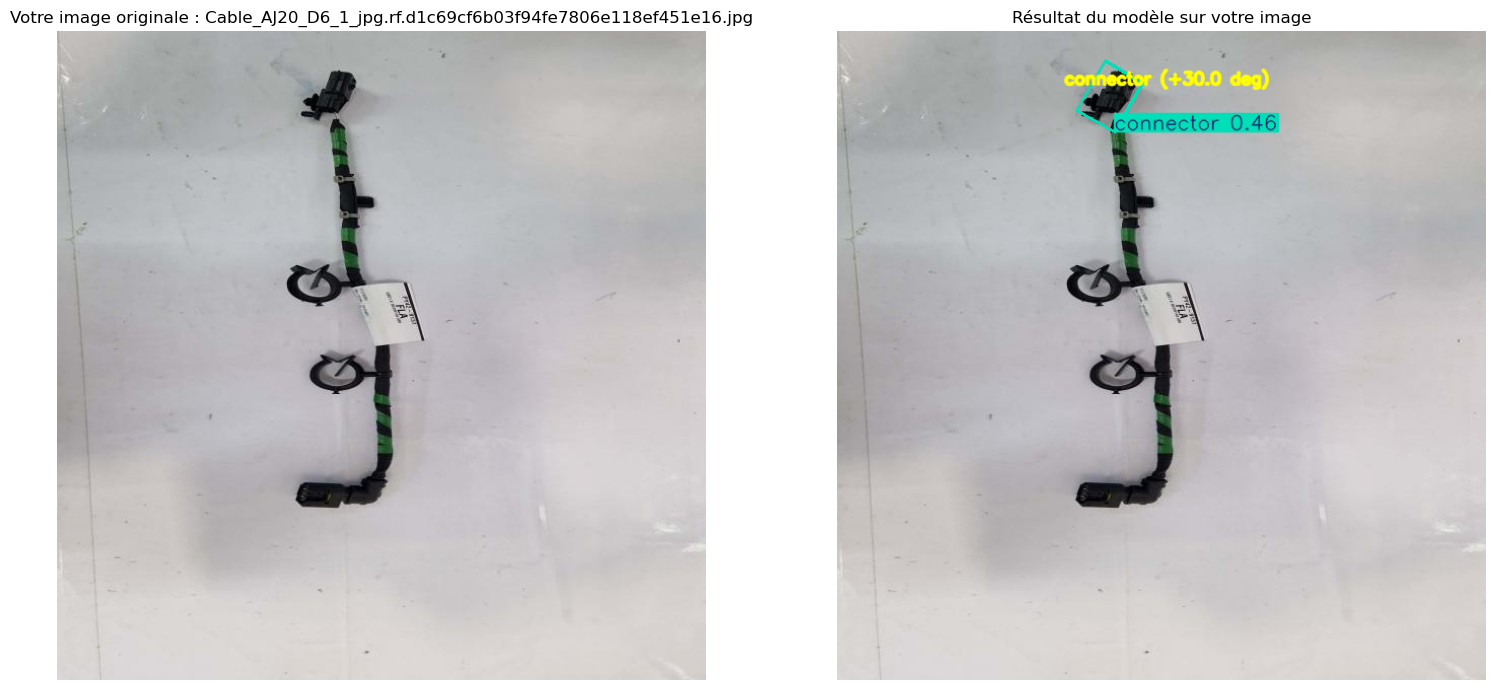

,id,classe,confiance,centre_x,centre_y,largeur_px,hauteur_px,angle_deg
0,0,connector,0.464,269.0,64.7,42.9,56.1,30.02


Image résultat enregistrée : D:\S5\Projet_d_expertise\projet\tests\resultat_Cable_AJ20_D6_1_jpg.rf.d1c69cf6b03f94fe7806e118ef451e16.png


In [21]:
vis = res.plot()
for skel in skel_overlays:
    vis[skel > 0] = (255, 255, 0)

# Ajout de l'angle écrit directement sur l'image si modèle OBB
if not df_res.empty and "angle_deg" in df_res.columns:
    for _, r in df_res.iterrows():
        txt = f"{r['classe']} ({r['angle_deg']:+.1f} deg)"
        cv2.putText(
            vis,
            txt,
            (max(5, int(r["centre_x"]) - 45), max(20, int(r["centre_y"]) - 12)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 255, 255),
            2,
            cv2.LINE_AA,
        )

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Votre image originale : {IMAGE_PATH.name}")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("Résultat du modèle sur votre image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

if not df_res.empty:
    display(df_res)
else:
    print("Aucun objet détecté. Essayez de réduire CONF_THRESHOLD (ex. 0.15) dans le Bloc 1.")

out_img = Path(f"resultat_{IMAGE_PATH.stem}.png").resolve()
cv2.imwrite(str(out_img), vis)
print(f"Image résultat enregistrée : {out_img}")